## MLOps Semana 4 - Exploración de datos

### Oscar Elton (A01840474)

Este notebook tiene solo el **EDA**. La limpieza reproducible vive está en el script `prepare_data.py`, que genera un csv limpio a partir de los datos crudos originales para poder reproducir.
El entrenamiento/registro en MLflow está en `train.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.2f}'.format)
SEED = 42

In [2]:
cols = ['id', 'source_type', 'operation_type', 'property_type', 'currency', 'asking_price',
        'm2_built', 'no_bedrooms', 'no_full_bathrooms', 'no_half_bathrooms', 'no_parking_spaces',
        'lat', 'lon', 'state', 'del_mun', 'neighborhood']

fuentes = ['i24', 'lamudi', 'propiedades', 'remax']

raw = pd.concat(
    [pd.read_csv(f'../data/raw/{f}.zip', usecols=cols, low_memory=False) for f in fuentes],
    ignore_index=True,
)

print(raw.shape)
raw['source_type'].value_counts()

(1365281, 16)


source_type
PROPIEDADES.COM    684066
lamudi             376051
i24                271641
Remax               33523
Name: count, dtype: int64

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1365281 entries, 0 to 1365280
Data columns (total 16 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   id                 1365281 non-null  object 
 1   operation_type     1365281 non-null  str    
 2   property_type      1365280 non-null  str    
 3   source_type        1365281 non-null  str    
 4   lat                1177032 non-null  float64
 5   lon                1177016 non-null  float64
 6   currency           1365184 non-null  str    
 7   asking_price       1365022 non-null  float64
 8   m2_built           1288834 non-null  object 
 9   no_bedrooms        1222139 non-null  object 
 10  no_full_bathrooms  1238014 non-null  object 
 11  no_half_bathrooms  286694 non-null   float64
 12  no_parking_spaces  1061836 non-null  object 
 13  neighborhood       1331189 non-null  str    
 14  del_mun            1364881 non-null  str    
 15  state              1364883 non-null  str   

In [4]:
raw['operation_type'].value_counts()

operation_type
Venta             891314
sale              215969
Renta             168788
rent               55672
venta              25941
renta               7582
Compra y renta        15
Name: count, dtype: int64

In [5]:
raw['property_type'].value_counts().head(25)

property_type
Casa                         674220
Departamento                 446181
Casa en condominio            58703
Lote / Terreno                49698
Casa-remate                   20578
Oficina                       17378
Casa en Fraccionamiento       16320
Tienda / Local Comercial      15873
Nave Industrial / Bodega      14760
Casa en Condominio            11232
Rancho                         7328
Terreno                        5995
Departamento-remate            5311
Edificio                       2434
Local - Comercial              2078
Terreno - Comercial            1901
Lote Comercial                 1597
Local en Centro Comercial      1558
Oficina - Comercial            1542
Condominio Horizontal          1407
Quinta                         1155
Quinta / Hacienda               933
Rancho / Huerta                 659
Bodega - Comercial              655
Penthouse                       646
Name: count, dtype: int64

In [6]:
raw['state'].value_counts().head(10)

state
Ciudad de México    126242
Yucatán             120506
DF / CDMX           113183
Nuevo León          103964
Jalisco              91746
Quintana Roo         87981
Querétaro            81174
México               73177
Puebla               52873
Estado de México     49954
Name: count, dtype: int64

**Primer filtro de las propiedades que nos interesan**
- Operación: `rent` / `renta` (se ignora mayúscula/minúscula).
- Tipo: `Departamento`, `Loft`, `Estudio`, `Penthouse`, `Dúplex`.
- Estado: `Ciudad de México` y `DF / CDMX`

In [7]:
df = raw[
    raw['operation_type'].str.lower().isin(['rent', 'renta'])
    & raw['property_type'].isin(['Departamento', 'Loft', 'Estudio', 'Penthouse', 'Dúplex'])
    & raw['state'].isin(['Ciudad de México', 'DF / CDMX'])
].copy()

print(df.shape)
df['property_type'].value_counts()

(22083, 16)


property_type
Departamento    21980
Loft               63
Penthouse          18
Estudio            17
Dúplex              5
Name: count, dtype: int64

In [8]:
df.head()

,id,operation_type,property_type,source_type,lat,lon,currency,asking_price,m2_built,no_bedrooms,no_full_bathrooms,no_half_bathrooms,no_parking_spaces,neighborhood,del_mun,state
73,141933064,rent,Departamento,i24,19.34,-99.31,MXN,NaN,37-114,NaN,1-2,NaN,1-1,Santa Fe Cuajimalpa,Cuajimalpa de Morelos,Ciudad de México
77,148293070,rent,Departamento,i24,19.43,-99.21,MXN,NaN,100-118,NaN,2-2,NaN,1-1,Polanco,Miguel Hidalgo,Ciudad de México
138,144968760,rent,Departamento,i24,19.44,-99.20,MXN,NaN,43-71,NaN,1-2,NaN,1-1,Polanco,Miguel Hidalgo,Ciudad de México
152,90867014,rent,Departamento,i24,19.42,-99.18,MXN,NaN,43-83,NaN,1-2,NaN,NaN,Roma Norte,Cuauhtémoc,Ciudad de México
162,144183867,rent,Departamento,i24,19.39,-99.25,MXN,NaN,58-114,NaN,1-2,NaN,1-1,Bosques de las Lomas,Cuajimalpa de Morelos,Ciudad de México


In [9]:
df.dtypes

id                    object
operation_type           str
property_type            str
source_type              str
lat                  float64
lon                  float64
currency                 str
asking_price         float64
m2_built              object
no_bedrooms           object
no_full_bathrooms     object
no_half_bathrooms    float64
no_parking_spaces     object
neighborhood             str
del_mun                  str
state                    str
dtype: object

In [10]:
num_cols = ['asking_price', 'm2_built', 'no_bedrooms', 'no_full_bathrooms',
            'no_half_bathrooms', 'no_parking_spaces', 'lat', 'lon']

no_nulos_antes = df[num_cols].notna().sum()
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')

# Cuántos valores no numéricos se volvieron NaN en cada columna?
no_nulos_antes - df[num_cols].notna().sum()

asking_price         0
m2_built             7
no_bedrooms          0
no_full_bathrooms    7
no_half_bathrooms    0
no_parking_spaces    5
lat                  0
lon                  0
dtype: int64

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 22083 entries, 73 to 1364864
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 22083 non-null  object 
 1   operation_type     22083 non-null  str    
 2   property_type      22083 non-null  str    
 3   source_type        22083 non-null  str    
 4   lat                19339 non-null  float64
 5   lon                19338 non-null  float64
 6   currency           22083 non-null  str    
 7   asking_price       22076 non-null  float64
 8   m2_built           21729 non-null  float64
 9   no_bedrooms        21139 non-null  float64
 10  no_full_bathrooms  21665 non-null  float64
 11  no_half_bathrooms  2732 non-null   float64
 12  no_parking_spaces  16940 non-null  float64
 13  neighborhood       21855 non-null  str    
 14  del_mun            22083 non-null  str    
 15  state              22083 non-null  str    
dtypes: float64(8), object(1), str(7)
me


## EDA

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
lat,"19,339.00",19.39,0.66,-34.58,19.37,19.41,19.43,37.39
lon,"19,338.00",-99.14,2.29,-122.11,-99.21,-99.19,-99.16,0.00
asking_price,"22,076.00","302,944.30","37,454,306.05",0.00,"19,781.00","30,000.00","45,179.25","5,564,716,715.00"
m2_built,"21,729.00",133.76,757.80,0.00,62.00,90.00,140.00,"64,160.00"
no_bedrooms,"21,139.00",2.06,0.79,1.00,2.00,2.00,3.00,20.00
no_full_bathrooms,"21,665.00",1.81,0.93,0.00,1.00,2.00,2.00,41.00
no_half_bathrooms,"2,732.00",1.05,0.25,1.00,1.00,1.00,1.00,6.00
no_parking_spaces,"16,940.00",1.60,0.82,0.00,1.00,1.00,2.00,15.00


- `asking_price` va de 0 a miles de millones. Una renta de departamento no puede ser 0 ni de ese tamaño; seguramente hay precios de venta mal etiquetados o errores de captura
- `m2_built` tiene ceros y valores de decenas de miles de m²
- Hay departamentos con 20 recámaras o más de 40 baños, lo cual no es creíble
- `lat`/`lon` tienen valores fuera de México (como alguna latitud negativa)

In [13]:
df.isna().mean().mul(100).round(1).sort_values(ascending=False)

no_half_bathrooms   87.60
no_parking_spaces   23.30
lat                 12.40
lon                 12.40
no_bedrooms          4.30
no_full_bathrooms    1.90
m2_built             1.60
neighborhood         1.00
id                   0.00
operation_type       0.00
property_type        0.00
source_type          0.00
currency             0.00
asking_price         0.00
del_mun              0.00
state                0.00
dtype: float64

In [14]:
df.groupby('currency')['asking_price'].describe()

,count,mean,std,min,25%,50%,75%,max
currency,,,,,,,,
EUR,1.00,"6,500.00",NaN,"6,500.00","6,500.00","6,500.00","6,500.00","6,500.00"
MXN,"21,590.00","309,582.45","37,873,509.02",0.00,"20,000.00","30,000.00","46,950.00","5,564,716,715.00"
USD,485.00,"8,055.58","3,997.48",110.00,"5,700.00","7,000.00","10,000.00","42,000.00"


In [15]:
df['asking_price'] = np.where(df['currency'] == 'USD', df['asking_price']*17, df['asking_price'])
df['asking_price'] = np.where(df['currency'] == 'EUR', df['asking_price']*21, df['asking_price'])

df['asking_price'].describe()

count          22,076.00
mean          305,781.83
std        37,454,289.83
min                 0.00
25%            20,000.00
50%            31,000.00
75%            50,000.00
max     5,564,716,715.00
Name: asking_price, dtype: float64

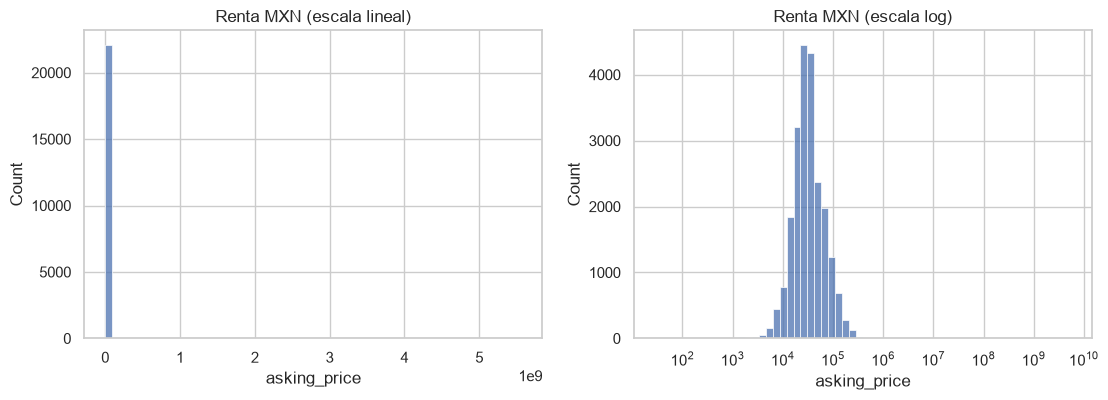

In [16]:
renta_mxn = df.loc[(df['asking_price'] > 0), 'asking_price']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(renta_mxn, bins=60, ax=axes[0])
axes[0].set_title('Renta MXN (escala lineal)')
sns.histplot(renta_mxn, bins=60, log_scale=True, ax=axes[1])
axes[1].set_title('Renta MXN (escala log)')
plt.show()

En escala lineal no se ve nada por los valores extremos. En escala log la distribución se ve más o menos simétrica alrededor de ~30 mil MXN, con colas a ambos lados que muy probablemente son errores.
Esto sugiere **modelar el logaritmo de la renta** como target mejor

In [17]:
renta_mxn.quantile([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999])

0.00       1,500.00
0.01       6,000.00
0.05      10,000.00
0.25      20,000.00
0.50      31,000.00
0.75      50,000.00
0.95     115,000.00
0.99     204,000.00
1.00   4,183,065.00
Name: asking_price, dtype: float64

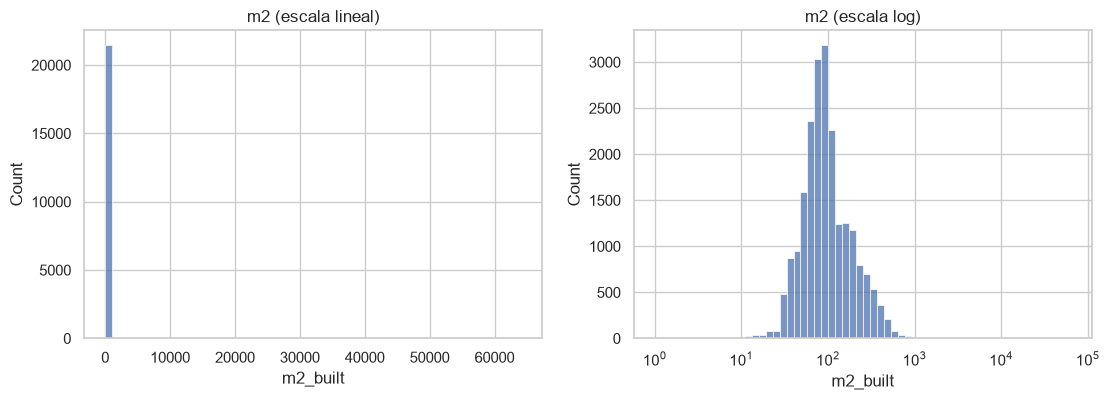

0.00     6.00
0.01    22.00
0.05    37.00
0.50    90.00
0.95   326.00
0.99   505.00
1.00   921.80
Name: m2_built, dtype: float64

In [18]:
m2 = df.loc[df['m2_built'] > 0, 'm2_built']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(m2, bins=60, ax=axes[0])
axes[0].set_title('m2 (escala lineal)')
sns.histplot(m2, bins=60, log_scale=True, ax=axes[1])
axes[1].set_title('m2 (escala log)')
plt.show()

m2.quantile([0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999])

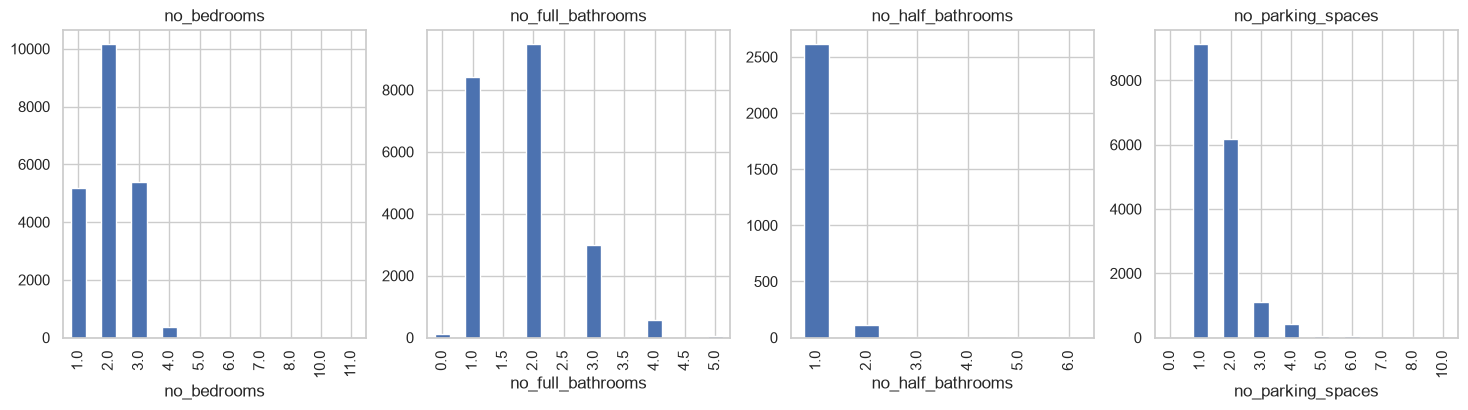

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, c in zip(axes, ['no_bedrooms', 'no_full_bathrooms', 'no_half_bathrooms', 'no_parking_spaces']):
    df[c].value_counts().sort_index().head(10).plot.bar(ax=ax, title=c)

plt.show()

In [20]:
df['del_mun'].value_counts()

del_mun
Miguel Hidalgo            6678
Cuauhtémoc                4919
Benito Juárez             2999
Cuajimalpa de Morelos     2505
Álvaro Obregón            1295
Alvaro Obregón             784
Coyoacán                   743
Tlalpan                    446
Azcapotzalco               414
Gustavo A. Madero          336
Ciudad de México           256
Venustiano Carranza        213
Iztacalco                  185
Iztapalapa                 140
La Magdalena Contreras      96
Xochimilco                  58
Tláhuac                     10
Milpa Alta                   5
otra                         1
Name: count, dtype: int64

In [21]:
print('Mismo id dentro del mismo portal:', df.duplicated(['source_type', 'id']).sum())

# Un mismo depto puede publicarse en varios portales: mismas características, precio y colonia. Esta medida es medio a dedo, 
# habría que probar otras cosas para desduplicar dando ciertos rangos de tolerancia..
cols_dup = ['asking_price', 'm2_built', 'no_bedrooms', 'no_full_bathrooms', 'no_parking_spaces', 'del_mun', 'neighborhood']
print('Mismas características y precio:', df.duplicated(cols_dup).sum())

Mismo id dentro del mismo portal: 66
Mismas características y precio: 4246



## Limpieza de datos

In [22]:
n_inicial = len(df)

In [23]:
n = len(df)
df['del_mun'] = df['del_mun'].replace({'Alvaro Obregón': 'Álvaro Obregón'})
df = df[~df['del_mun'].isin(['Ciudad de México', 'otra'])]
print('Eliminados:', n - len(df))
print('Alcaldías:', df['del_mun'].nunique())

Eliminados: 257
Alcaldías: 16


In [24]:
n = len(df)
df = df.drop_duplicates(['source_type', 'id'])
print('Duplicados por id:', n - len(df))

n = len(df)
df = df.drop_duplicates(cols_dup)
print('Duplicados por características y precio:', n - len(df))

Duplicados por id: 66
Duplicados por características y precio: 4310


In [25]:
n = len(df)
df = df.dropna(subset=['asking_price', 'm2_built', 'no_bedrooms', 'no_full_bathrooms', 'lat', 'lon'])

print('Eliminados:', n - len(df))

df.isna().mean().mul(100).round(1).sort_values(ascending=False).head(5)

Eliminados: 3085


no_half_bathrooms   87.50
no_parking_spaces   19.30
neighborhood         1.40
id                   0.00
operation_type       0.00
dtype: float64

In [26]:
n = len(df)
df = df[
    df['asking_price'].between(3_000, 100_000)
    & df['m2_built'].between(20, 300)
    & (df['no_bedrooms'] <= 4)
    & df['no_full_bathrooms'].between(1, 3)
    & ~(df['no_parking_spaces'] > 4)
]

print('Eliminados:', n - len(df))

Eliminados: 1948


In [27]:
n = len(df)
df['precio_m2'] = df['asking_price'] / df['m2_built']

lim_inf, lim_sup = df['precio_m2'].quantile([0.01, 0.99])

df = df[df['precio_m2'].between(lim_inf, lim_sup)]

print(f'Rango aceptado de precio/m²: {lim_inf:,.0f} – {lim_sup:,.0f} MXN')
print('Eliminados:', n - len(df))

Rango aceptado de precio/m²: 93 – 823 MXN
Eliminados: 250


In [28]:
n = len(df)
df = df[df['lat'].between(19.0, 19.6) & df['lon'].between(-99.4, -98.9)]
print('Eliminados por coordenadas fuera de CDMX:', n - len(df))

Eliminados por coordenadas fuera de CDMX: 13


In [29]:
print(f'Registros: {n_inicial:,} -> {len(df):,} ({len(df) / n_inicial:.0%} conservado)')
df.describe().T

Registros: 22,083 -> 12,154 (55% conservado)


,count,mean,std,min,25%,50%,75%,max
lat,"12,154.00",19.40,0.04,19.21,19.37,19.41,19.43,19.56
lon,"12,154.00",-99.19,0.04,-99.33,-99.21,-99.18,-99.16,-98.97
asking_price,"12,154.00","33,585.58","19,897.18","3,800.00","19,300.00","28,900.00","42,000.00","100,000.00"
m2_built,"12,154.00",103.91,55.75,20.00,65.00,90.00,125.00,300.00
no_bedrooms,"12,154.00",2.00,0.70,1.00,2.00,2.00,2.00,4.00
no_full_bathrooms,"12,154.00",1.74,0.65,1.00,1.00,2.00,2.00,3.00
no_half_bathrooms,"1,239.00",1.02,0.15,1.00,1.00,1.00,1.00,3.00
no_parking_spaces,"9,722.00",1.53,0.61,1.00,1.00,1.00,2.00,4.00
precio_m2,"12,154.00",337.33,134.78,93.02,239.05,317.92,416.67,822.37


### EDA con datos limpios

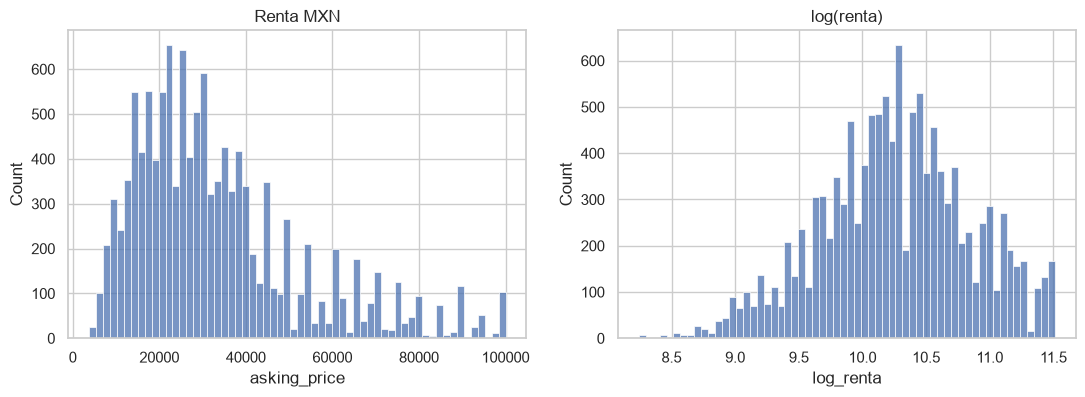

In [30]:
df['log_renta'] = np.log(df['asking_price'])
df['log_m2'] = np.log(df['m2_built'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['asking_price'], bins=60, ax=axes[0])
axes[0].set_title('Renta MXN')
sns.histplot(df['log_renta'], bins=60, ax=axes[1])
axes[1].set_title('log(renta)')
plt.show()

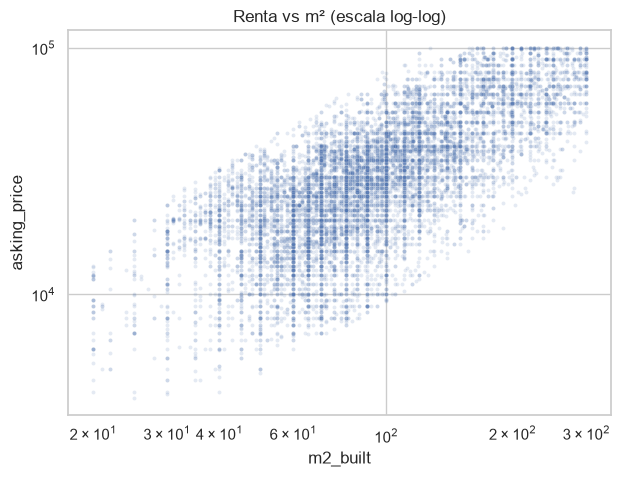

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x='m2_built', y='asking_price', alpha=0.15, s=8, ax=ax)
ax.set(xscale='log', yscale='log', title='Renta vs m² (escala log-log)')
plt.show()

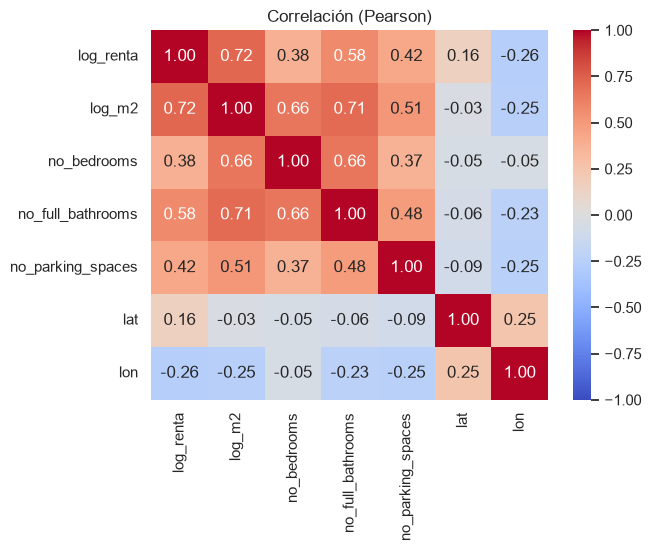

In [32]:
vars_corr = ['log_renta', 'log_m2', 'no_bedrooms', 'no_full_bathrooms', 'no_parking_spaces', 'lat', 'lon']
sns.heatmap(df[vars_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación (Pearson)')
plt.show()

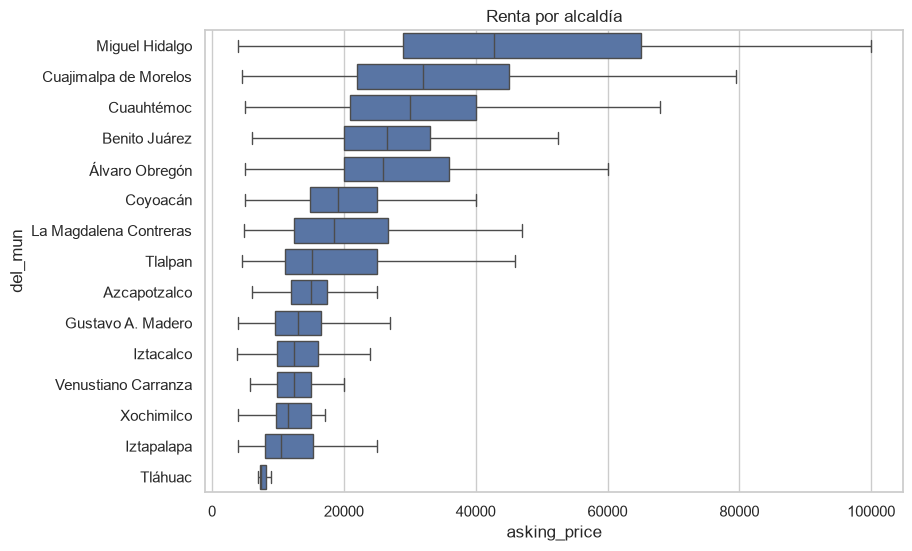

,count,median
del_mun,,
Miguel Hidalgo,3242,"42,800.00"
Cuajimalpa de Morelos,1413,"32,000.00"
Cuauhtémoc,2621,"30,000.00"
Benito Juárez,1925,"26,500.00"
Álvaro Obregón,1282,"26,000.00"
Coyoacán,486,"19,150.00"
La Magdalena Contreras,54,"18,500.00"
Tlalpan,280,"15,125.00"
Azcapotzalco,275,"15,000.00"


In [33]:
orden = df.groupby('del_mun')['asking_price'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, y='del_mun', x='asking_price', order=orden, showfliers=False, ax=ax)
ax.set_title('Renta por alcaldía')
plt.show()

df.groupby('del_mun')['asking_price'].agg(['count', 'median']).sort_values('median', ascending=False)

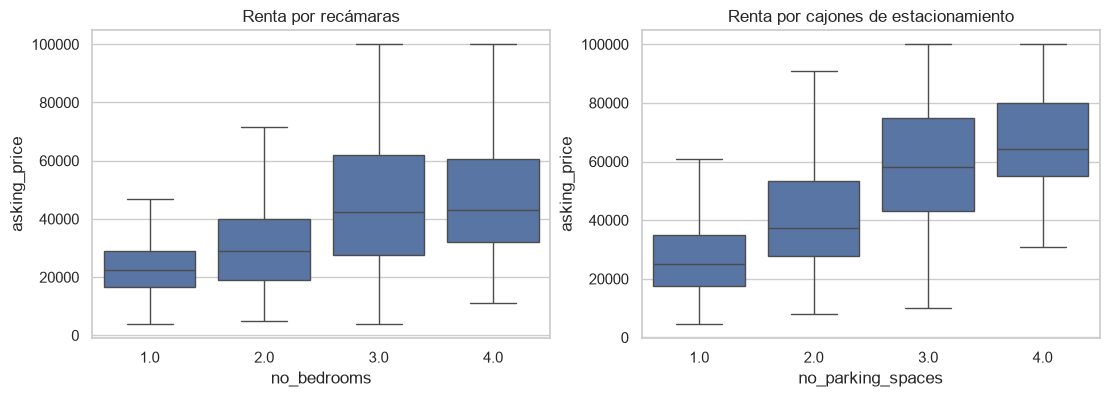

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='no_bedrooms', y='asking_price', showfliers=False, ax=axes[0])
axes[0].set_title('Renta por recámaras')
sns.boxplot(data=df, x='no_parking_spaces', y='asking_price', showfliers=False, ax=axes[1])
axes[1].set_title('Renta por cajones de estacionamiento')
plt.show()

In [35]:
df.groupby('property_type')['asking_price'].agg(['count', 'median'])

,count,median
property_type,,
Departamento,12125,"28,900.00"
Dúplex,1,"20,000.00"
Estudio,2,"13,000.00"
Loft,22,"18,750.00"
Penthouse,4,"43,750.00"
